所有断层图已绘制完成。


M 6.0-6.9 events plotted: 146 before 2000, 238 from 2000
 year  month  day  latitude  longitude  magnitude
 2005      3    6    24.630    121.930        6.0
 2005      3    6    24.720    121.920        6.0
 2011      9   17    40.300    143.100        6.0
 2007      9    7    24.380    122.030        6.0
 2000      9   10    24.080    121.630        6.0
 2018      1   24    41.130    142.370        6.0
 2011      4   12    36.900    140.800        6.0
 2018      8   17    23.480    143.300        6.0
 2013      1   29    42.550     79.750        6.0
 2022     11   14    33.800    137.400        6.0
 2022      3   23    23.390    121.520        6.0
 2009      7    9    25.600    101.030        6.0
 2014     12   11    25.450    122.400        6.0
 2011      3   11    39.130    143.030        6.0
 2011      3    9    38.410    143.020        6.0
 2012      6    6    35.020    141.410        6.0
 2011      3   12    37.290    141.780        6.0
 2011      3   19    39.700    143.100     

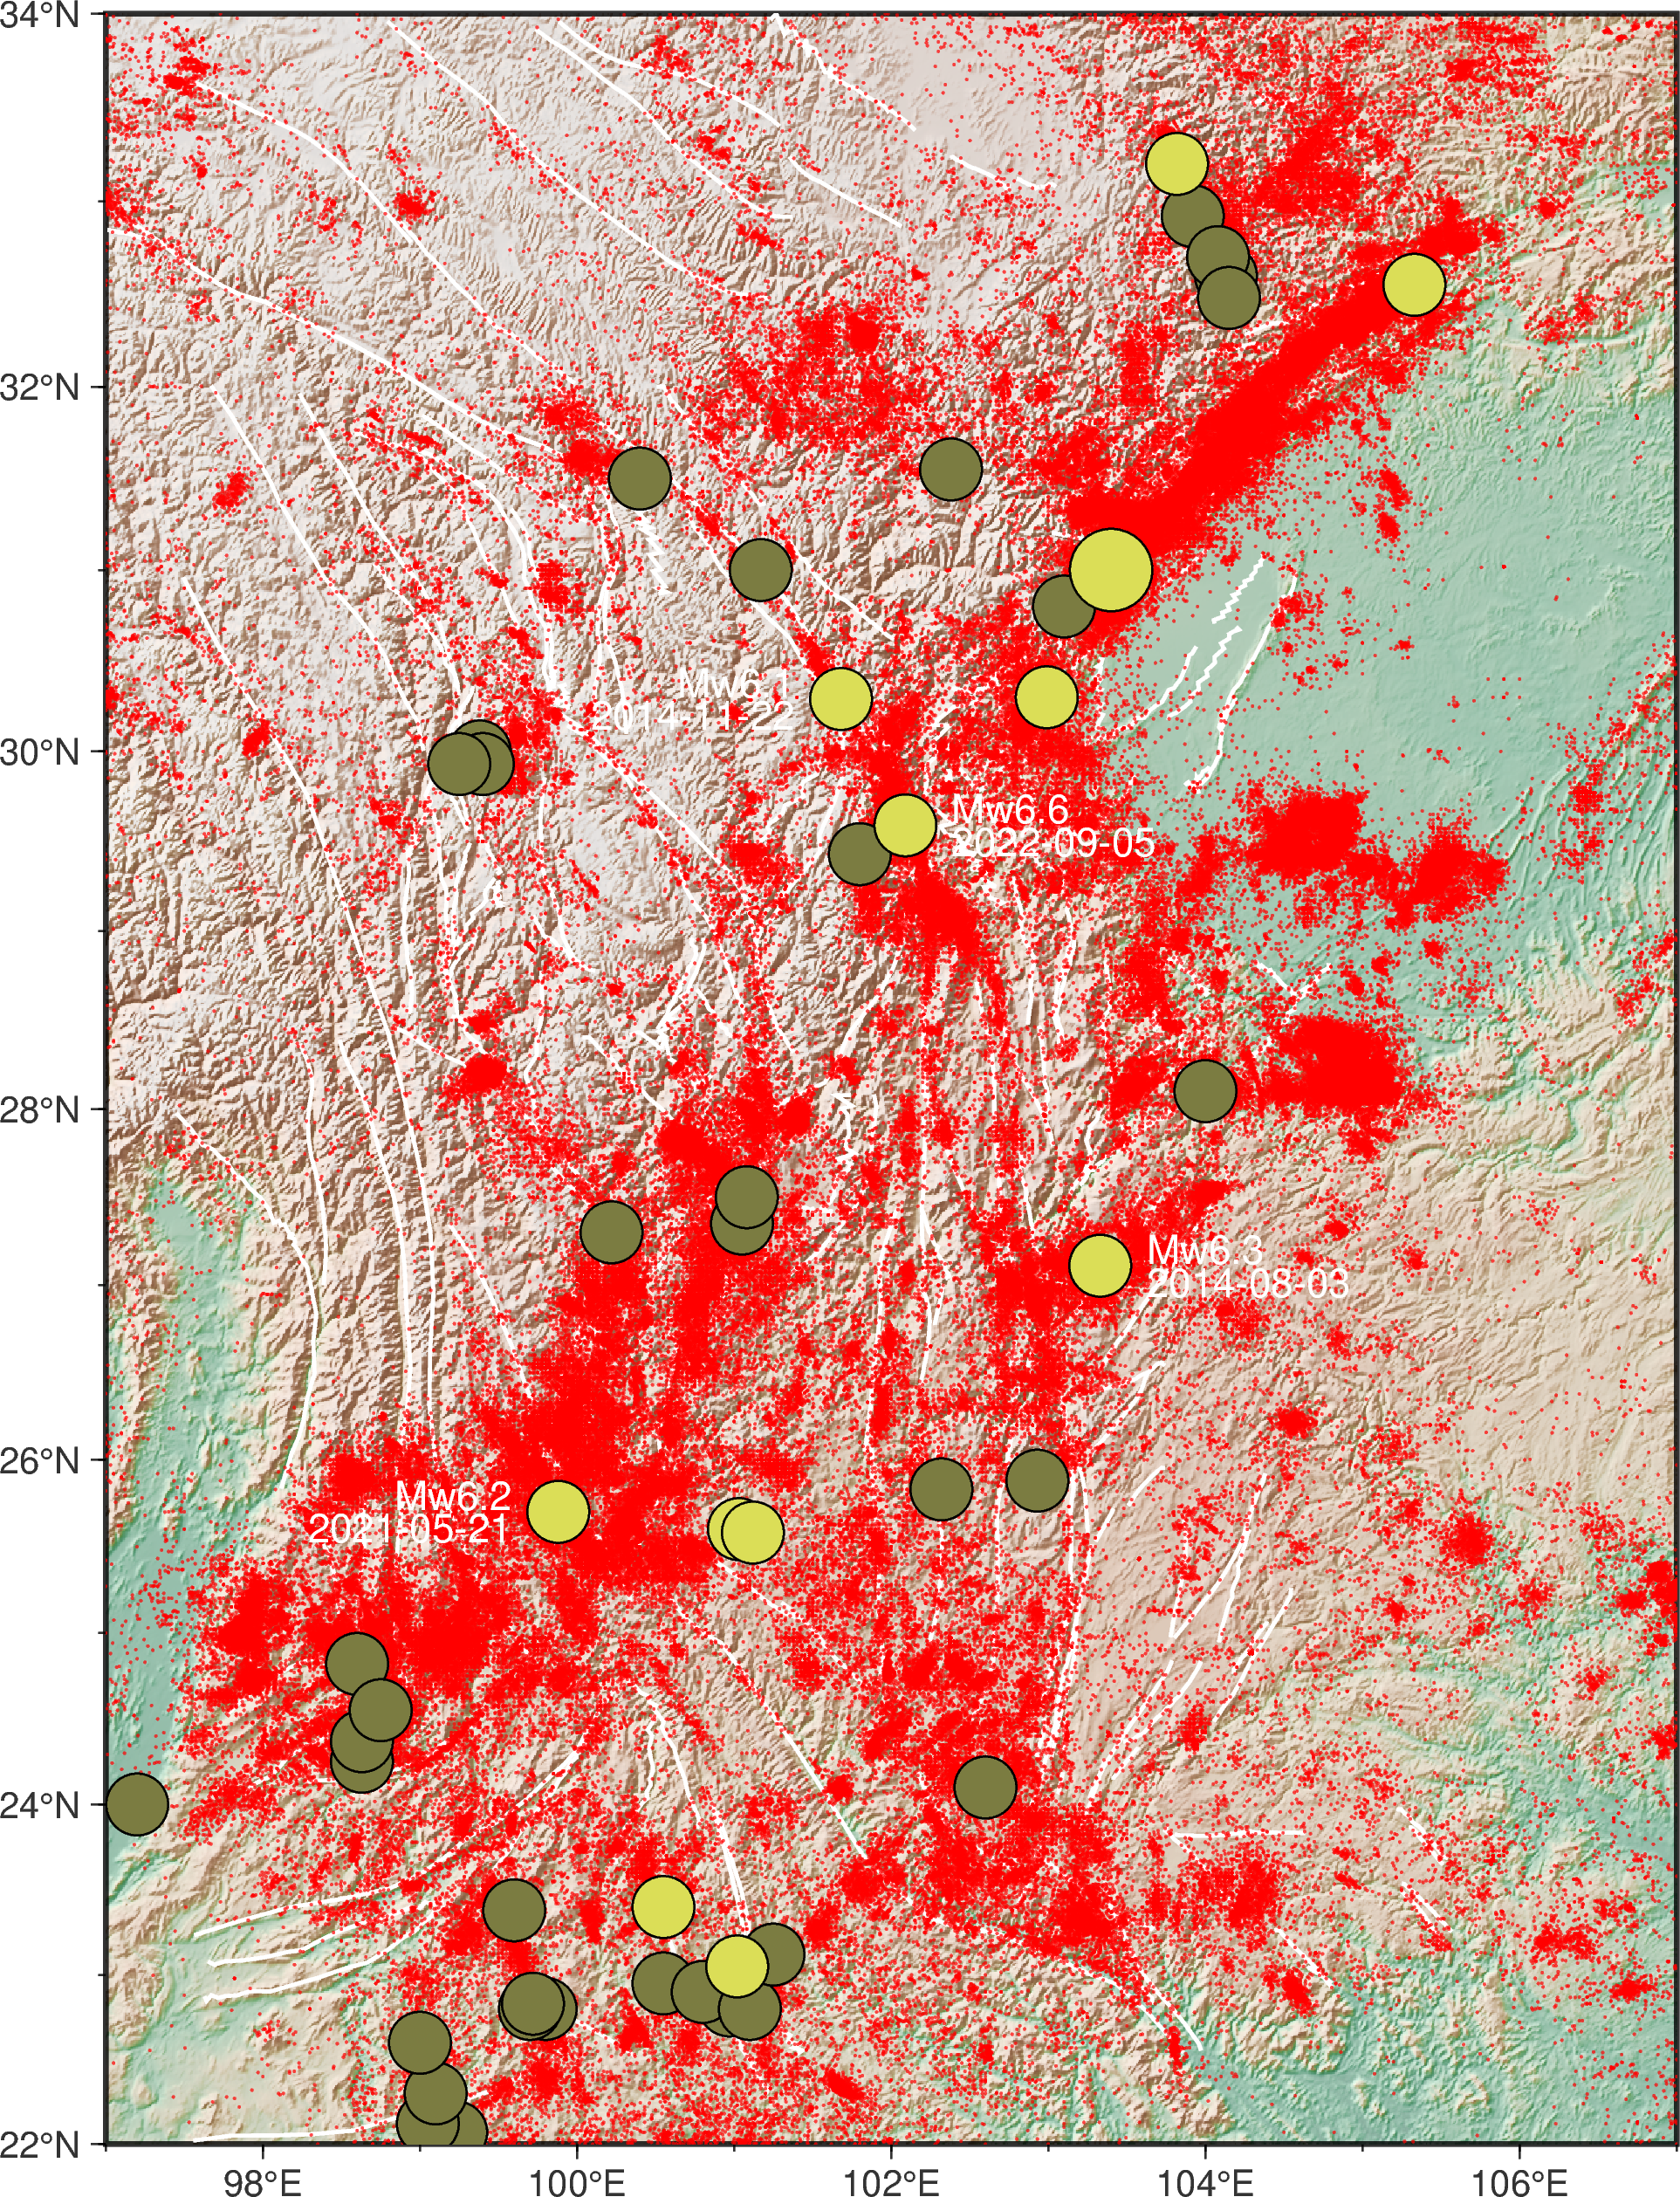

In [1]:
import subprocess
import pygmt
import pandas as pd
import os
pygmt.config(
    FONT_TITLE="10p,5", 
    MAP_TITLE_OFFSET="1p", 
    MAP_FRAME_TYPE="plain",     # 关键设置：plain表示黑线框，fancy表示黑白格
    MAP_ANNOT_OBLIQUE=6,
    MAP_FRAME_PEN="1.5p,black"  # 明确指定黑色
)
# 设置地图区域和投影
region = [97, 107, 22, 34]  # 经度范围: 99 到 106，纬度范围: 22 到 33
grid = pygmt.datasets.load_earth_relief(resolution='30s', region=region)

# 创建一个地图对象
fig = pygmt.Figure()

fig.grdimage(grid=grid, region=region, projection='M6i',cmap='terra',frame=True, shading=True, transparency=20)  

#fig.text(position="MC", text="PyGMT", font="80p,Helvetica-Bold,red@75")
# 添加颜色条（colorbar）
# fig.colorbar(
#     cmap="light_gray.cpt",     # 使用与图像相同的 CPT 文件
#     position="JMR+o0.5c/0c+w10c/0.5c",  # 设置颜色条位置和大小
#     frame=["xaf+lElevation (m)"],  # 添加标签，单位为米
# )


# 读取转换后的经纬度数据
data_file = "../faults/processed_fault_data.txt"  # 你的数据文件路径
data = pd.read_csv(data_file, sep=r"\s+", header=None, 
                   names=[ "FaultName", "Longitude", "Latitude"])
# 筛选出在该区域内的断层数据
data = data[
    (data["Longitude"] >= region[0]) & (data["Longitude"] <= region[1]) & 
    (data["Latitude"] >= region[2]) & (data["Latitude"] <= region[3])
]
fault_names = data['FaultName'].unique()

# 遍历每个 Faultname 分组并绘图

for fault in fault_names:
    # 筛选出当前 Faultname 的数据
    
    fault_data = data[data['FaultName'] == fault]
  
    fig.plot(x=fault_data["Longitude"], y=fault_data["Latitude"], pen="1p,white", label="Active fault")
    # 添加标题（显示 Faultname）
    # fig.text(
    #     x=midpoint_x,  # 调整位置到图形左上角
    #     y=midpoint_y,
    #     text=f"Fault: {fault}",
    #     font="12p,Helvetica-Bold,black",
    #     offset="0.2c"
    # )
# 结束循环
print("所有断层图已绘制完成。")
# 添加活断层，假设有一个断层线文件“faults.gmt”
# 读取转换后的经纬度数据
# shaoqiao_file = "/Users/chouyuhin/_Harvard/b-value/b_value/plotting/faults/大凉山断裂坐标.txt"  # 你的数据文件路径
# shaoqiao = pd.read_csv(shaoqiao_file, delim_whitespace=True, header=None, 
#                    names=["Longitude", "Latitude"])
# fig.plot(x=shaoqiao["Longitude"], y=shaoqiao["Latitude"], pen="1.5p, white  ", label="Active fault")

# puduhe_file = "/Users/chouyuhin/_Harvard/b-value/b_value/plotting/faults/xianshuihe.txt"  # 你的数据文件路径
# puduhe = pd.read_csv(puduhe_file, delim_whitespace=True, header=None, 
#                    names=["Longitude", "Latitude"])
# fig.plot(x=puduhe["Longitude"], y=puduhe["Latitude"], pen="1.5p,black", label="Active fault")

# xiaojiangdong_file = "/Users/chouyuhin/_Harvard/b-value/b_value/plotting/faults/小江断裂东支坐标.txt"  # 你的数据文件路径
# xiaojiangdong = pd.read_csv(xiaojiangdong_file, delim_whitespace=True, header=None, 
#                    names=["Longitude", "Latitude"])
# fig.plot(x=xiaojiangdong["Longitude"], y=xiaojiangdong["Latitude"], pen="1.5p,black", label="Active fault")

# xiaojiangdong_file = "/Users/chouyuhin/_Harvard/b-value/b_value/plotting/faults/小江断裂西支坐标.txt"  # 你的数据文件路径
# xiaojiangdong = pd.read_csv(xiaojiangdong_file, delim_whitespace=True, header=None, 
#                    names=["Longitude", "Latitude"])
# fig.plot(x=xiaojiangdong["Longitude"], y=xiaojiangdong["Latitude"], pen="1.5p,black", label="Active fault")

# xiaojiangxi_file = "/Users/chouyuhin/_Harvard/b-value/b_value/plotting/faults/anninghe.txt"  # 你的数据文件路径
# xiaojiangxi = pd.read_csv(xiaojiangxi_file, delim_whitespace=True, header=None, 
#                    names=["Longitude", "Latitude"])
# fig.plot(x=xiaojiangxi["Longitude"], y=xiaojiangxi["Latitude"], pen="1.5p,black", label="Active fault")

# zemuhe_file = "/Users/chouyuhin/_Harvard/b-value/b_value/plotting/faults/则木河断裂坐标.txt"  # 你的数据文件路径
# zemuhe = pd.read_csv(zemuhe_file, delim_whitespace=True, header=None, 
#                    names=["Longitude", "Latitude"])
# fig.plot(x=zemuhe["Longitude"], y=zemuhe["Latitude"], pen="1.5p,black", label="Active fault")

# zhaoqiao_file = "G:/BHT/昭巧断裂坐标.txt"  # 你的数据文件路径
# zhaoqiao = pd.read_csv(zhaoqiao_file, delim_whitespace=True, header=None, 
#                    names=["Longitude", "Latitude"])
# fig.plot(x=zhaoqiao["Longitude"], y=zhaoqiao["Latitude"], pen="1.5p,black", label="Active fault")
# print("所有活断层已绘制完成。")

# 读取所有地震目录
columns = ["year", "month", "day", "hour", "minute", "second", "latitude", "longitude", "depth", "magnitude_type", "magnitude"]
data_all = pd.read_csv("../../../catalogs/CENCcat_Mw_final.txt", sep=r"\s+", header=None, names=columns)
# 筛选出在该区域内的断层数据

# 震级小于5
data_small = data_all[data_all["magnitude"] <7]

fig.plot(
    x=data_all["longitude"],
    y=data_all["latitude"],
    style="c0.03c", 
    #size=0.05 * (1.5**data_before_2000['magnitude']),  # 根据震级设置半径
    fill="red",
    transparency=30,
)

# 读取城市坐标文件（绘制白色填充黑色边框的圆点）
# cities = pd.read_csv("/Users/chouyuhin/_Harvard/b-value/b_value/catalogs/keycities.txt", sep=" ", header=None, names=["city","longitude", "latitude"], 
#                     usecols=[0,1, 2], dtype={"longitude": float, "latitude": float})

# fig.plot(x=cities["longitude"], y=cities["latitude"], style="c0.2c", fill="yellow", pen="0.5p,white",transparency=20)
# # 读取城市坐标（绘制白色填充黑色边框的圆点）

# # 6. 添加城市标签
# for i, row in cities.iterrows():
#     fig.text(x=row["longitude"], y=row["latitude"], text=row["city"], font="12p,black", justify="LT")


# 读取5级以上地震目录
# 读取文件数据，并命名列
columns = ["year", "month", "day", "hour", "minute", "second", "latitude", "longitude", "depth", "magnitude_type", "magnitude"]

# 读取文件

data_before_2000 = data_all[data_all["year"] < 2000]
data_from_2000 = data_all[data_all["year"] >= 2000]
# 按震级大小画圆，以免被覆盖
data_before_2000 = data_before_2000.sort_values(by="magnitude", ascending=True)
data_from_2000 = data_from_2000.sort_values(by="magnitude", ascending=True)




# # 震级5.0-5.9
# data_before_2000_56 = data_before_2000[(data_before_2000["magnitude"] >= 5) & (data_before_2000["magnitude"] < 6)]
# data_from_2000_56 = data_from_2000[(data_from_2000["magnitude"] >= 5) & (data_from_2000["magnitude"] < 6)]

# # 绘制 5-5.9 数据 
# #fig.plot(
# #    x=data_before_2000_56["longitude"],
# #    y=data_before_2000_56["latitude"],
# #    style="c0.35c",  # 基本圆圈样式，后续会缩放
# #    #size=0.05 * (1.5**data_before_2000['magnitude']),  # 根据震级设置半径
# #    fill="#7b7c41",
# #   
# #    pen="0.5p,black"  # 黑色边界
# #)
# #fig.plot(
# #    x=data_from_2000_56["longitude"],
# #    y=data_from_2000_56["latitude"],
# #    style="c0.35c",  # 基本圆圈样式，后续会缩放
# #    #size=0.05 * (1.5**data_from_2000['magnitude']),  # 根据震级设置半径
# #    fill="#dbde57",
# #   
# #    pen="0.5p,black"  # 黑色边界
# #)

# 6.0-6.9
# 6.0-6.9 (Reviewer 1, comment 11a: all M >= 6 events of the converted catalog are plotted)
data_before_2000_67 = data_before_2000[(data_before_2000["magnitude"] >= 6) & (data_before_2000["magnitude"] < 7)]
data_from_2000_67 = data_from_2000[(data_from_2000["magnitude"] >= 6) & (data_from_2000["magnitude"] < 7)]
fig.plot(x=data_before_2000_67["longitude"], y=data_before_2000_67["latitude"], style="c0.6c", fill="#7b7c41", pen="0.5p,black")
fig.plot(x=data_from_2000_67["longitude"], y=data_from_2000_67["latitude"], style="c0.6c", fill="#dbde57", pen="0.5p,black")
print("M 6.0-6.9 events plotted:", len(data_before_2000_67), "before 2000,", len(data_from_2000_67), "from 2000")
print(data_from_2000_67[["year", "month", "day", "latitude", "longitude", "magnitude"]].to_string(index=False))

#7-7.9
# M >= 6 at 0.6 cm and M >= 7.5 at 0.8 cm, as in the original figure (Wenchuan: Ms 8.0 in the raw catalog, Mw 7.9 here)
data_before_2000_78 = data_before_2000[(data_before_2000["magnitude"] >= 7) & (data_before_2000["magnitude"] < 7.5)]
data_from_2000_78 = data_from_2000[(data_from_2000["magnitude"] >= 7) & (data_from_2000["magnitude"] < 7.5)]
# 绘制 6-6.9 数据 
fig.plot(
    x=data_before_2000_78["longitude"],
    y=data_before_2000_78["latitude"],
    style="c0.6c",  # 基本圆圈样式，后续会缩放
    #size=0.05 * (1.5**data_before_2000['magnitude']),  # 根据震级设置半径
    fill="#7b7c41",
   
    pen="0.5p,black"  # 黑色边界
)
fig.plot(
    x=data_from_2000_78["longitude"],
    y=data_from_2000_78["latitude"],
    style="c0.6c",  # 基本圆圈样式，后续会缩放
    #size=0.05 * (1.5**data_from_2000['magnitude']),  # 根据震级设置半径
    fill="#dbde57",
   
    pen="0.5p,black"  # 黑色边界
)
# for i, row in data_before_2000_78.iterrows():
#     fig.text(x=row["longitude"], y=row["latitude"], text=f"{row["year"]}+{row["month"]}+{row["day"]}+{row["magnitude_type"]}+{row["magnitude"]}", font="12p,black", justify="LT")
# for i, row in data_from_2000_78.iterrows():
#     fig.text(x=row["longitude"], y=row["latitude"], text=f"{row["year"]}+{row["month"]}+{row["day"]}+{row["magnitude_type"]}+{row["magnitude"]}", font="12p,black", justify="LT")
# #8-8.9
data_before_2000_89 = data_before_2000[data_before_2000["magnitude"] >= 7.5]
data_from_2000_89 = data_from_2000[data_from_2000["magnitude"] >= 7.5]
# print(data_before_2000_89)
# print(data_from_2000_89)
# fig.plot(
#     x=data_before_2000_89["longitude"],
#     y=data_before_2000_89["latitude"],
#     style="c1.1c",  # 基本圆圈样式，后续会缩放
#     #size=0.05 * (1.5**data_before_2000['magnitude']),  # 根据震级设置半径
#     fill="#7b7c41",
   
#     pen="0.5p,black"  # 黑色边界
# )
fig.plot(x=data_before_2000_89["longitude"], y=data_before_2000_89["latitude"], style="c0.8c", fill="#7b7c41", pen="0.5p,black")
fig.plot(
    x=data_from_2000_89["longitude"],
    y=data_from_2000_89["latitude"],
    style="c0.8c",  # 基本圆圈样式，后续会缩放
    #size=0.05 * (1.5**data_from_2000['magnitude']),  # 根据震级设置半径
    fill="#dbde57",
   
    pen="0.5p,black"  # 黑色边界
)
# ；
# columns = ['year', 'month', 'day', 'hour', 'minute', 'second', 'latitude', 'longitude', 'anything', 'mag_type', 'magnitude', 'datetime']
# bigEQ = pd.read_csv("/Users/chouyuhin/_Harvard/b-value/b_value/bigEQs.csv", delim_whitespace=',', header=None, names=columns)
# # 绘制地震事件为五角星符号
# fig.plot(
#     x=bigEQ["longitude"],
#     y=bigEQ["latitude"],
#     style="a0.6c",  # 五角星符号，大小为0.4厘米，可根据需求调整
#     fill="red",
#     pen="0p,white"  # 黑色边框
# )
# # 6. 添加大震标签
# # for i, row in bigEQ.iterrows():
# #     fig.text(x=row["longitude"], y=row["latitude"], text=row["location"], font="12p,black", justify="LT")
# 2. 绘制矩形框
# lms_box_lon = [101.8, 104.7, 104.7, 101.8, 101.8]
# lms_box_lat = [26,  26,  28, 28,  26]

# fig.plot(
#     x=lms_box_lon,
#     y=lms_box_lat,
#     pen="2.5p,white",
#     label="Longmenshan Area" # 图例标签（如果后续添加图例会显示）
# )

# labels for the M >= 6 events the reviewer could not find (Reviewer 1, comment 11a); style of the old Fig. 2
# side: label to the right (R) or left (L) of the circle, so it does not run into a neighbouring circle
for yr, mo, dy, name, side in [(2014, 11, 22, 'Kangding', 'L'), (2014, 8, 3, 'Ludian', 'R'), (2021, 5, 21, 'Yangbi', 'L'), (2022, 9, 5, 'Luding', 'R')]:
    ev = data_all[(data_all["year"] == yr) & (data_all["month"] == mo) & (data_all["day"] == dy) & (data_all["magnitude"] >= 6)]
    ev = ev[(ev["longitude"] > region[0]) & (ev["longitude"] < region[1]) & (ev["latitude"] > region[2]) & (ev["latitude"] < region[3])]
    if len(ev) == 0:
        print("label skipped, event not found:", name, yr, mo, dy); continue
    r = ev.iloc[0]
    fig.text(x=r["longitude"], y=r["latitude"], text=f"Mw{r['magnitude']:.1f}", font="11p,Helvetica,white", justify=("LB" if side == "R" else "RB"), offset=("0.45c/0.02c" if side == "R" else "-0.45c/0.02c"))
    fig.text(x=r["longitude"], y=r["latitude"], text=f"{yr}-{mo:02d}-{dy:02d}", font="11p,Helvetica,white", justify=("LT" if side == "R" else "RT"), offset=("0.45c/-0.02c" if side == "R" else "-0.45c/-0.02c"))
    print("labelled", name, yr, mo, dy, r["longitude"], r["latitude"], r["magnitude"])
fig.show()
# # 保存为 EPS 格式，设置分辨率
# # 2. 输出高兼容性PDF（保留矢量元素）
fig.savefig("Fig2_chuandian.pdf")
